# P2 / 04: frozen VIX-gated S05, independent replication on 2017–2019 (15 minutes)

Protocol: [`003_claude_p2_frozen_spec_replication_2017_2019.md`](../../discussions/Liquidity_Provision/003_claude_p2_frozen_spec_replication_2017_2019.md). Frozen specification from notebook 03, unchanged: S05 0.1.3, `x10` exits, entries only after closes with VIX above its trailing 250-session median, S05b-method measured costs (new quote samples for 2017–2019).

**Gates** (α = 0.05, as notebook 03): V1 high − low regime gross per trade > 0 in `ALL`; V2 `VIX` beats 200 circularly shifted regimes on net return and Sharpe; V3 `VIX` net > 0 at 1× and 2×, bootstrap lower bound > 0 at blocks 10/20/40. `REPLICATED` only if all three pass.

In [1]:
N_PLACEBO = 200
N_JOBS = -1

import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, p1, p2, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("P2_SYNTHETIC") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
CFG = p2.P2Config()
PER_YEAR, WINDOW_S = 4, 3.0                          # S05b quote samples (reused from cache)
YEARS_D = list(range(2016, 2026))                    # 1Day bars; 2016 is baseline warm-up
YEARS_Q = list(range(2020, 2026))                    # measured-cost years; 2026 not used
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"15Min_w{WINDOW_S:g}s"
SCFG = s05.S05Config(close_long=1.0, close_short=-1.0, n_placebo=N_PLACEBO)     # x10 exits (S05c)
YEARS = [2017, 2018, 2019]                          # independent sample; 2026 sealed
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 8
tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_s05{s05.S05_VERSION}_p{s04.PANEL_VERSION}_p2{p2.P2_VERSION}"
OUT = ROOT / "notebooks" / "Liquidity_Provision" / ("04_synthetic" if SYNTHETIC else "04")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "p2_04" / tag
CACHE.mkdir(parents=True, exist_ok=True)
QCACHE = vendor_dir("Alpaca") / "quote_samples" / f"{SCFG.timeframe}_w{WINDOW_S:g}s"
QCACHE.mkdir(parents=True, exist_ok=True)
ACOL = {"ALL": "#444444", "VIX": "#2a78d6"}
if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | exits x10 | placebos={N_PLACEBO}")

synthetic=False | exits x10 | placebos=200


In [2]:
# frozen specification (protocol 003, section 1): stop if anything differs
FROZEN = {"s05_version": "0.1.3", "close_long": 1.0, "close_short": -1.0, "open_long": -1.25, "open_short": 1.25,
          "window_sessions": 20, "size_per_stock": 0.01, "max_positions": 100, "vix_window": 250, "vix_min": 200}
got = {"s05_version": s05.S05_VERSION, **{k: getattr(SCFG, k) for k in ("close_long", "close_short", "open_long", "open_short",
       "window_sessions", "size_per_stock", "max_positions")}, "vix_window": CFG.vix_window, "vix_min": CFG.vix_min}
assert got == FROZEN, {k: (got[k], FROZEN[k]) for k in FROZEN if got[k] != FROZEN[k]}
print("frozen specification confirmed")

frozen specification confirmed


## 1. Data, measured costs, estimation (as P1/02), VIX regime on panel days

In [3]:
# step 1/4: 15-minute bars 2017-2019 (cached after the first run) and the separate panel cache
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + ["SPY"], SCFG.timeframe, YEARS, workers=8)
    print("building / loading the 2017-2019 panel ...", flush=True)
    panel = p2.panel_cache(STOCKS + ETFS + ["SPY"], SCFG.timeframe, YEARS, CACHE / "panel_15Min_2017_2019.npz", ffill_bars=SCFG.ffill_bars)
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
QUOTED = sorted(set(TRADED) | {ETF_OF[s] for s in TRADED})
print(f"panel {panel.c.shape}, traded {len(TRADED)} (absent from the panel: {sorted(set(STOCKS) - have)[:15]}...) in {time.time() - t0:.0f}s")

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
building / loading the 2017-2019 panel ...
panel (19508, 492), traded 480 (absent from the panel: ['ABNB', 'APP', 'CARR', 'CEG', 'COIN', 'DASH', 'FDXF', 'FERG', 'GEHC', 'GEV', 'HONA', 'HOOD', 'HWM', 'KVUE', 'OTIS']...) in 3s


In [4]:
# step 2/4: quote samples for 2017-2019 (S05b method). Rate-limited: several minutes per session.
# Each finished session is saved to QCACHE as <date>.parquet; an interrupted run resumes from the last finished session.
SESSIONS = s05b.sample_sessions(YEARS, PER_YEAR, seed=42)
if SYNTHETIC:
    samples = pd.DataFrame([(s, 3e-4, 10, k, d) for d in SESSIONS for k in range(26) for s in QUOTED],
                           columns=["symbol", "half_spread", "n_quotes", "slot", "date"])
else:
    todo = [d for d in SESSIONS if not (QCACHE / f"{d}.parquet").exists()]
    print(f"{len(SESSIONS) - len(todo)}/{len(SESSIONS)} sessions cached in {QCACHE}; sampling {len(todo)}", flush=True)
    t0 = time.time()
    for k, d in enumerate(todo, 1):
        t1 = time.time()
        sample_quote_spreads(QUOTED, d, s05b.slot_starts(YEARS, d), window_s=WINDOW_S, cache_dir=QCACHE)
        el = time.time() - t0
        print(f"  {d}: {(time.time() - t1) / 60:.1f} min | {k}/{len(todo)} done, ~{el / k * (len(todo) - k) / 60:.0f} min left", flush=True)
    samples = pd.concat([pd.read_parquet(QCACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
print(f"{len(samples):,} quote-sample rows; median half-spread {1e4 * samples.half_spread.median():.2f} bps")

5/12 sessions cached in D:\MarketData\Alpaca\quote_samples\15Min_w3s; sampling 7
  2018-03-15: 7.2 min | 1/7 done, ~43 min left
  2018-07-12: 9.0 min | 2/7 done, ~40 min left
  2018-09-07: 8.9 min | 3/7 done, ~33 min left
  2019-02-19: 7.2 min | 4/7 done, ~24 min left
  2019-07-08: 11.5 min | 5/7 done, ~18 min left
  2019-09-17: 11.0 min | 6/7 done, ~9 min left
  2019-10-11: 10.5 min | 7/7 done, ~0 min left
153,192 quote-sample rows; median half-spread 1.76 bps


In [5]:
# step 3/4: cost array and S05 estimates
t0 = time.time()
H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    P = s05.estimate_all(panel, SC, EC, SCFG, s05.first_decision_day(SCFG)); np.savez(est_path, **P)
print(f"costs median {np.median(H[:, SC]) * 1e4:.2f} bps; estimates ready in {time.time() - t0:.0f}s")

costs median 2.04 bps; estimates ready in 17s


In [6]:
# step 4/4: VIX regime on panel sessions
DAYS = pd.DatetimeIndex(pd.to_datetime(list(panel.days)))
if SYNTHETIC:
    VIX = p2.synthetic_vix(pd.bdate_range("2023-01-01", "2025-12-31"))
else:
    VIX = p2.load_vix()
REG = p2.vix_regime(VIX, CFG).reindex(DAYS)
REG_VALID = REG.notna().to_numpy()
REG_ON = REG.fillna(False).astype(bool).to_numpy()
print(f"regime known on {REG_VALID.mean():.1%} of sessions, high on {REG_ON[REG_VALID].mean():.1%}")

regime known on 100.0% of sessions, high on 46.3%


## 2. Backtests (1×, 2×, 0×)

6 backtests in 0.3 min; trading starts 2017-02-02


,total_return,sharpe,max_drawdown,mean_daily,days
ALL 1x,-0.0607,-0.7189,0.0749,-0.0001,732.0
ALL 2x,-0.1297,-1.6278,0.1365,-0.0002,732.0
ALL 0x,0.0123,0.1622,0.0472,0.0000,732.0
VIX 1x,-0.0481,-0.6852,0.0568,-0.0001,732.0
VIX 2x,-0.0984,-1.4585,0.1032,-0.0001,732.0
VIX 0x,0.0083,0.1286,0.0376,0.0000,732.0


,trades,mean_gross_bps,cost_per_trade_bps,avg_open_positions,gross_over_cost
ALL,7775.0,1.607,10.046,99.983,0.169
VIX,5396.0,1.480,10.557,65.476,0.107


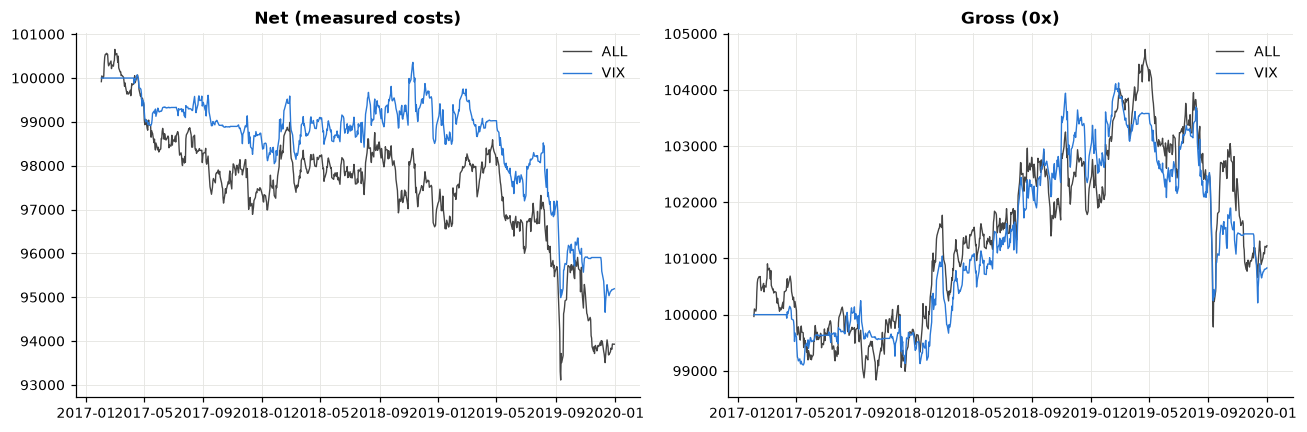

In [7]:
MASK = {"ALL": None, "VIX": p2.regime_mask(REG_ON, len(SC))}
runs, rows, tstats = {}, {}, {}
t0 = time.time()
for arm, m in MASK.items():
    for cm in (1.0, 2.0, 0.0):
        runs[(arm, cm)] = s05.backtest(panel, P, SC, EC, replace(SCFG, cost_mult=cm), record=(cm == 1.0), half_spread=H, entry_mask=m)
START = runs[("ALL", 1.0)]["first_day"]
for (arm, cm), r in runs.items():
    rows[f"{arm} {cm:g}x"] = s04.perf_metrics(r["daily_equity"], SCFG.initial_equity, START)
for arm in MASK:
    r = runs[(arm, 1.0)]; tr = r["trades"]
    tstats[arm] = {"trades": len(tr), "mean_gross_bps": 1e4 * tr.gross_ret.mean() if len(tr) else np.nan,
                   "cost_per_trade_bps": 1e4 * r["total_cost"] / tr.notional.sum() if len(tr) else np.nan,
                   "avg_open_positions": float(r["n_open"][panel.index.tz_localize(None) >= START].mean()),
                   "gross_over_cost": tr.gross_pnl.sum() / r["total_cost"] if r["total_cost"] > 0 else np.nan}
    tr.drop(columns=["i"]).to_csv(OUT / f"trades_{arm}.csv", index=False, float_format="%.6g")
    r["daily_equity"].to_csv(OUT / f"daily_equity_{arm}.csv", header=["equity"], float_format="%.2f")
METRICS = pd.DataFrame(rows).T
print(f"{len(runs)} backtests in {(time.time() - t0) / 60:.1f} min; trading starts {START.date()}")
display(METRICS.round(4)); display(pd.DataFrame(tstats).T.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for arm in MASK:
    for cm, i in ((1.0, 0), (0.0, 1)):
        e = runs[(arm, cm)]["daily_equity"]; e = e[e.index >= START]
        ax[i].plot(e.index, e, color=ACOL[arm], lw=0.9, label=arm)
ax[0].set_title("Net (measured costs)"); ax[1].set_title("Gross (0x)")
for a in ax: a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. V1: gross per trade by regime at entry, `ALL` run

In [8]:
tr = runs[("ALL", 1.0)]["trades"].copy()
lrow = p1.trade_label_rows(tr["entry_bar"].to_numpy(), panel.day_start)
ok = (lrow >= 0) & REG_VALID[np.clip(lrow, 0, None)]
tr = tr[ok].copy(); lrow = lrow[ok]
tr["regime_high"] = REG_ON[lrow].astype(int); tr["entry_day"] = lrow
BYR = tr.groupby("regime_high").agg(trades=("gross_ret", "size"), mean_gross_bps=("gross_ret", lambda x: 1e4 * x.mean()),
                                     median_bars=("bars", "median"))
BYR.to_csv(OUT / "all_run_by_regime.csv", float_format="%.5g"); display(BYR.round(3))
V1 = p1.cluster_bootstrap_diff(tr["gross_ret"].to_numpy(), tr["regime_high"].to_numpy(), tr["entry_day"].to_numpy(), 1, 0, 10_000, SCFG.seed, 0.05)
print(f"high - low regime gross per trade: {1e4 * V1[0]:.2f} bps, 95% [{1e4 * V1[1]:.2f}, {1e4 * V1[2]:.2f}]")

,trades,mean_gross_bps,median_bars
regime_high,,,
0,4024,-2.712,241.0
1,3751,6.240,231.0


high - low regime gross per trade: 8.95 bps, 95% [-10.21, 28.12]


## 4. V2: against circularly shifted regimes

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   12.2s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:   53.9s
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  2.0min


200 placebos in 2.5 min


[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  2.5min finished


,value,percentile,p_upper,placebo_median,placebo_p95
total_return,-0.0481,39.5,0.6070,-0.0429,-0.0019
sharpe,-0.6852,43.5,0.5672,-0.6225,-0.0225


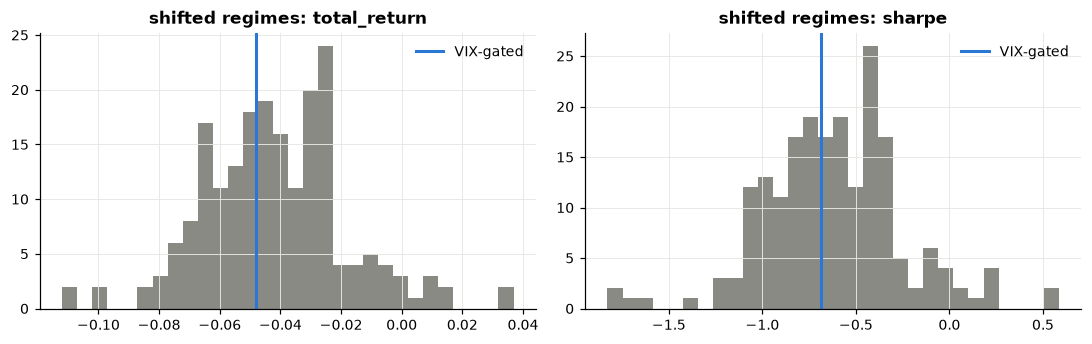

In [9]:
from joblib import Parallel, delayed
pl_path = CACHE / f"placebo_shift_{N_PLACEBO}.parquet"
if pl_path.exists():
    PL = pd.read_parquet(pl_path)
else:
    t0 = time.time()
    seeds = [SCFG.seed * 1000 + i for i in range(N_PLACEBO)]
    regs = [p2.shifted_regime(REG_ON, np.random.default_rng(s), CFG.min_shift if not SYNTHETIC else 20, REG_VALID) for s in seeds]
    PL = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=1, verbose=5)(
        delayed(p2.run_regime_backtest)(panel, P, SC, EC, SCFG, r, s, START, H) for s, r in zip(seeds, regs)))
    PL.to_parquet(pl_path); print(f"{N_PLACEBO} placebos in {(time.time() - t0) / 60:.1f} min")
PL.to_csv(OUT / "placebo_shifted_regime.csv", index=False, float_format="%.6g")
vm = METRICS.loc["VIX 1x"]
RANKS = {k: s04.placebo_rank(vm[k], PL[k].to_numpy()) for k in ("total_return", "sharpe")}
display(pd.DataFrame(RANKS).T.round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, k in zip(ax, ("total_return", "sharpe")):
    a.hist(PL[k], bins=30, color="#8a8a84"); a.axvline(vm[k], color=ACOL["VIX"], lw=2, label="VIX-gated")
    a.set_title(f"shifted regimes: {k}"); a.legend(frameon=False)
plt.tight_layout(); plt.show()

In [10]:
# reported, not judged: per-year net returns
YR = {}
for arm in MASK:
    e = runs[(arm, 1.0)]["daily_equity"]; r = e[e.index >= START].pct_change().dropna()
    YR[arm] = r.groupby(r.index.year).apply(lambda x: (1 + x).prod() - 1)
YR = pd.DataFrame(YR); YR.to_csv(OUT / "net_by_year.csv", float_format="%.5g"); display((100 * YR).round(2))

,ALL,VIX
2017,-2.45,-1.26
2018,-0.34,0.33
2019,-3.31,-3.90


## 5. Gates

In [11]:
e = runs[("VIX", 1.0)]["daily_equity"]; e = e[e.index >= START]
BOOT = {b: s04.block_bootstrap_mean(e.pct_change().dropna().to_numpy(), b, 10_000, SCFG.seed) for b in (10, 20, 40)}
G = p2.gates_15m(V1, RANKS, METRICS.loc["VIX 1x"].to_dict(), METRICS.loc["VIX 2x"].to_dict(), BOOT)
G["replication_verdict"] = "REPLICATED" if (G["V1_regime_dependence"] and G["V2_vs_shifted_regime"] and G["V3_economic"]) else "NOT_REPLICATED"
display(pd.DataFrame(BOOT, index=["mean", "lo95", "hi95"]).T)
summary = {"study": "P2-04", "synthetic": SYNTHETIC, "years": YEARS, "config": SCFG.as_dict(), "p2_config": CFG.as_dict(),
           "trading_start": str(START.date()), "n_placebo": N_PLACEBO, "metrics": METRICS.to_dict(orient="index"), "trade_stats": tstats,
           "all_run_by_regime": BYR.to_dict(orient="index"), "V1_high_minus_low_gross": {"mean": V1[0], "lo95": V1[1], "hi95": V1[2]},
           "placebo_shift_ranks": RANKS, "bootstrap_VIX": {str(k): v for k, v in BOOT.items()}, "gates": G, "net_by_year": {str(k): v for k, v in YR.to_dict(orient="index").items()},
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "panel": s04.PANEL_VERSION, "p2": p2.P2_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps(G, indent=2))

,mean,lo95,hi95
10,-0.000066,-0.000175,0.000034
20,-0.000066,-0.000161,0.000024
40,-0.000066,-0.000150,0.000012


{
  "V1_regime_dependence": false,
  "V2_vs_shifted_regime": false,
  "V3_economic": false,
  "verdict": "NO_EDGE",
  "prospective_verdict": "PENDING_2026_HOLDOUT",
  "replication_verdict": "NOT_REPLICATED"
}
